# Mean accuracy and expression ranking, one figure (paper appendix A.1)

Paper version of the two figures of `app:accuracy`, merged into one. Sources: `three_channels_analysis/canal_1/canal1_classic_aleatoric.ipynb`, cell 7 (mean performance) and cell 8 (expression).

**Why they merge cleanly.** Both are drawn along the SAME shared gene ordering (cross-model, donor-averaged Pearson, decreasing), so a given `n` denotes the same gene set on all three rows.

| row | quantity | models enter? |
|---|---|---|
| a | cumulative mean Pearson on log1p-CP10k | yes, one curve per head |
| b | paired difference to the mean-only baseline, within donor | yes, baseline IS the zero line |
| c | mean measured expression, log1p-CP10k | **no** — a property of the data; only the x ordering comes from the models |


In [9]:
import sys
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))   # parent dir of src (notebooks are not pip-installed on the cluster)

import src.evaluation.benchmark_summary as bs
importlib.reload(bs)
from src.evaluation.benchmark_summary import (
    discover_run_summaries, cutoff_donor_points, paired_deltas_full,
    gene_donor_matrix, donor_lopo_stats,
)

RUN_ID    = "pr_classic3"
DATASETS  = ["10x_TuPro", "TLS", "LUNG_CANCER"]
RADIUS    = "r75"
REFERENCE = "msemeanonly"                      # the mean-only baseline row b argues against
NS        = [50, 100, 500, 1000, 2000, None]   # None -> the full shared panel

# log1p(CP10k) axis ONLY. The depth-blind *_raw pair reports on log1p(raw counts) and must never
# share an axis with these.
CP_MODELS = ["msemeanonly", "homoscedastic", "heteroscedastic", "spot_homoscedastic",
             "poisson_cp", "negativebinomial_hetero_noanchor_cp",
             "negativebinomial_spotdisp_cp", "negativebinomial_genedisp_cp"]

FIGDIR = PROJ / "results" / "_analysis" / "figures_paper"

summaries = discover_run_summaries(PROJ / "results", RUN_ID, DATASETS,
                                   radius=RADIUS, models=CP_MODELS, lambda_keep=0.0)
print(f"{len(summaries)} runs charges")
for s in summaries:
    print(f"   {s['dataset']:<12s} {s['label']}")

# Without the baseline, every delta cell silently produces empty tables; failing here
# rather than there: the most likely cause is that canal1 has not written yet
# benchmark_summary.parquet.
_found = {s["label"].split("|")[0] for s in summaries}
assert REFERENCE in _found, (
    f"reference {REFERENCE!r} absent from the loaded runs ({sorted(_found)}). "
    f"did canal1 run on this model?")
_missing = [m for m in CP_MODELS if m not in _found]
if _missing:
    print(f"\n(!) models requested but not found: {_missing}")

24 runs charges
   10x_TuPro    heteroscedastic|lam0.0
   10x_TuPro    homoscedastic|lam0.0
   10x_TuPro    msemeanonly
   10x_TuPro    negativebinomial_genedisp_cp
   10x_TuPro    negativebinomial_hetero_noanchor_cp
   10x_TuPro    negativebinomial_spotdisp_cp
   10x_TuPro    poisson_cp
   10x_TuPro    spot_homoscedastic|lam0.0
   TLS          heteroscedastic|lam0.0
   TLS          homoscedastic|lam0.0
   TLS          msemeanonly
   TLS          negativebinomial_genedisp_cp
   TLS          negativebinomial_hetero_noanchor_cp
   TLS          negativebinomial_spotdisp_cp
   TLS          poisson_cp
   TLS          spot_homoscedastic|lam0.0
   LUNG_CANCER  heteroscedastic|lam0.0
   LUNG_CANCER  homoscedastic|lam0.0
   LUNG_CANCER  msemeanonly
   LUNG_CANCER  negativebinomial_genedisp_cp
   LUNG_CANCER  negativebinomial_hetero_noanchor_cp
   LUNG_CANCER  negativebinomial_spotdisp_cp
   LUNG_CANCER  poisson_cp
   LUNG_CANCER  spot_homoscedastic|lam0.0


## 1. The three rows, and their printed twins

Row a comes from `cutoff_donor_points`, row b from `paired_deltas_full`, both of which rebuild the SAME gene ordering internally, so the two rows cannot drift apart. Row c rebuilds that ordering explicitly (`shared_gene_order`) because the expression table carries no Pearson to sort on: without it, `n = 500` would not denote the same 500 genes on row c as on rows a and b.

Row c's interval is the same family as the others (Student-$t$ over the K per-donor points) but is **descriptive**: it says how much the expression level itself varies between patients, never that a model generalizes. Under LOPO each donor is the test donor exactly once and all its spots form that fold's test split, so "all spots of donor d" and "the test spots of donor d" are the same set and the per-donor means align with the models' per-donor points with no population shift to justify.

In [10]:
# -- ROW a: per-model cumulative curve + donor t-CI ---------------------------------------------
points = cutoff_donor_points(summaries, ns=NS, metrics=("pearson",))
rows = []
for (ds, model, n), g in points.groupby(["dataset", "model", "n"]):
    st = donor_lopo_stats(dict(zip(g["donor"], g["value"])))
    rows.append(dict(dataset=ds, model=model, n=n, mean=st["mean"],
                     lo=st["ci95_mean"][0], hi=st["ci95_mean"][1]))
curves = pd.DataFrame(rows)

# -- ROW b: paired delta vs the mean-only baseline ----------------------------------------------
# The difference is taken WITHIN each donor, which removes the donor effect that dominates the
# raw spread and gives intervals ~10x tighter than those of row a.
deltas = paired_deltas_full(summaries, reference=REFERENCE, metrics=("pearson",), ns=NS)
print(f"{len(deltas)} deltas (dataset x cutoff x model)")

# -- ROW c: mean measured expression along the SAME ordering ------------------------------------
# Per-gene expression stats, MODEL-INDEPENDENT, precomputed by
# snake/scripts/canals/dataset_gene_expression_stats_precompute.py. The PER-DONOR version is
# the one needed: a Student interval needs K per-donor points, the dataset-wide table
# crushes them into a single number per gene. It lives in the SHARED results/_analysis tree.
GENE_EXPR_DONOR_PARQUET = PROJ / "results" / "_analysis" / "gene_expression_stats_per_donor.parquet"
assert GENE_EXPR_DONOR_PARQUET.is_file(), (
    f"absent : {GENE_EXPR_DONOR_PARQUET}\n"
    "-> a single CPU job, model-independent: "
    "bash snake/scripts/canals/launch_dataset_gene_expression_stats_precompute.sh")

expr_donor_df = pd.read_parquet(GENE_EXPR_DONOR_PARQUET)
EXPR_DONOR_BY_DS = {ds: g.pivot_table(index="gene", columns="donor", values="mean_log1p_cp10k")
                    for ds, g in expr_donor_df.groupby("dataset")}
print(f"gene_expression_stats_per_donor : {len(expr_donor_df):,} rows (dataset, donor, gene)")


def shared_gene_order(ds):
    """The gene ranking of rows a and b, rebuilt here.

    cutoff_donor_points / paired_deltas_full rebuild it internally and do not return it, so
    these few lines replicate it identically: gene set SHARED by the loaded models, ranked by
    Pearson averaged over the donors then across models, descending. Without this,
    'n = 500' would not designate the same 500 genes on row c.
    """
    group = [s for s in summaries if s["dataset"] == ds]
    assert len({s["gene_set"] for s in group}) == 1, f"{ds} : several gene_sets, ambiguous order"
    shared, pieces = None, []
    for s in group:
        mat = gene_donor_matrix(s["per_long"], "pearson")
        shared = set(mat.index) if shared is None else (shared & set(mat.index))
        pieces.append(mat.mean(axis=1))
    shared = sorted(shared)
    return pd.concat(pieces, axis=1).loc[shared].mean(axis=1).sort_values(ascending=False).index


rows = []
for ds in DATASETS:
    order = shared_gene_order(ds)
    mat = EXPR_DONOR_BY_DS[ds].reindex(order)      # (gene x donor), in the order of the curves
    n_missing = int(mat.isna().all(axis=1).sum())
    if n_missing:
        print(f"(!) {ds} : {n_missing}/{len(order)} panel genes absent from the expression parquet")
    for n in sorted({len(order) if k is None else min(int(k), len(order)) for k in NS}):
        st = donor_lopo_stats(mat.iloc[:n].mean(axis=0, skipna=True).to_dict())  # genes -> K points
        rows.append(dict(dataset=ds, n=int(n), K=st["K"], mean=st["mean"], sd=st["sd"],
                         sem=st["sem"], lo=st["ci95_mean"][0], hi=st["ci95_mean"][1]))
expr_curves = pd.DataFrame(rows)

NS_PLOT = sorted(curves["n"].unique())
print(f"cutoffs : {NS_PLOT}")

# The printed twin is NOT here: it is in the FIGURE cell, fed by what was actually
# drawn. Printing from these tables would let through a model present in the numbers and
# absent from the figure, which is exactly what a twin must prevent.

# The n axis is a PREDICTABILITY axis (the ranking is done on the Pearson), not an expression
# axis: a ratio > 1 says the best predicted genes are also the most expressed.
print("\n=== are the best predicted genes the most expressed? (min n vs full panel) ===")
for ds in DATASETS:
    cur = expr_curves[expr_curves["dataset"] == ds].sort_values("n")
    a, b = cur.iloc[0], cur.iloc[-1]
    print(f"   {ds:<12s} n={int(a['n']):<5d} {a['mean']:.4f}  ->  n={int(b['n']):<5d} "
          f"{b['mean']:.4f}   ratio {a['mean'] / b['mean']:.2f}x")

126 deltas (dataset x cutoff x model)
gene_expression_stats_per_donor : 332,162 rows (dataset, donor, gene)
cutoffs : [np.int64(50), np.int64(100), np.int64(500), np.int64(1000), np.int64(2000), np.int64(3000)]

=== are the best predicted genes the most expressed? (min n vs full panel) ===
   10x_TuPro    n=50    1.3761  ->  n=3000  0.4454   ratio 3.09x
   TLS          n=50    1.2278  ->  n=3000  0.2001   ratio 6.13x
   LUNG_CANCER  n=50    1.3308  ->  n=3000  0.2952   ratio 4.51x


## 2. The merged paper figure — 3 rows x 3 cohorts

y axes are independent from one panel to the next, as in the source figures: the three cohorts are not at the same expression level and a common axis would flatten two of the three curves. Cross-cohort comparison is read off the printed table, not off panel heights.

Knobs: `ROW_H`, `COL_W`, `LEGEND_FS`, `LEGEND_GUTTER`, `BOTTOM_PAD`.

legend strip = 0.211 of the width -> 2.23 in per panel
written: fig_mean_performance_expression_paper_pr_classic3.pdf


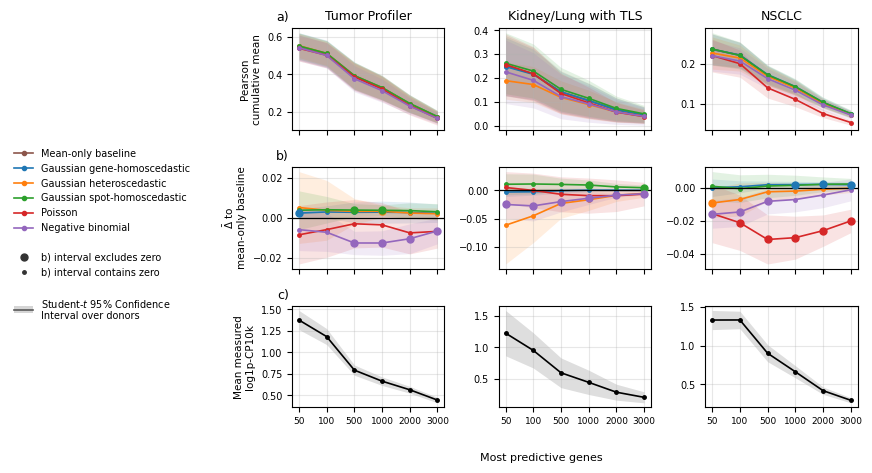


PRINTED TWIN - row a) cumulative Pearson  [mean (95% donor CI on the mean)]

--- Tumor Profiler ---
n                                                       50                       100                      500                      1000                     2000                     3000
model                                                                                                                                                                                    
msemeanonly                          0.5471 (0.4756, 0.6187)  0.5075 (0.4369, 0.5780)  0.3892 (0.3163, 0.4622)  0.3258 (0.2611, 0.3905)  0.2412 (0.1948, 0.2876)  0.1721 (0.1399, 0.2043)
homoscedastic                        0.5495 (0.4780, 0.6211)  0.5105 (0.4394, 0.5815)  0.3921 (0.3185, 0.4656)  0.3287 (0.2635, 0.3939)  0.2439 (0.1968, 0.2910)  0.1744 (0.1416, 0.2072)
heteroscedastic                      0.5523 (0.4887, 0.6159)  0.5113 (0.4475, 0.5751)  0.3925 (0.3215, 0.4635)  0.3292 (0.2653, 0.3931)  0.2437 (0.1974, 0.

In [11]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.legend_handler import HandlerTuple

# Canonical model -> color map, keyed on model_type (NOT the |lam label): a positional scheme
# silently recolors a model when the loaded set changes.
MODEL_COLORS = {
    "msemeanonly":                         "#8c564b",   # brown  -- the mean-only baseline
    "homoscedastic":                       "#1f77b4",   # blue
    "heteroscedastic":                     "#ff7f0e",   # orange
    "spot_homoscedastic":                  "#2ca02c",   # green
    "poisson_cp":                          "#d62728",   # red    -- Poisson family
    "negativebinomial_hetero_noanchor_cp": "#9467bd",   # purple -- NB family, free dispersion
}
MODEL_LABELS = {
    "msemeanonly":                         "Mean-only baseline",
    "homoscedastic":                       "Gaussian gene-homoscedastic",
    "heteroscedastic":                     "Gaussian heteroscedastic",
    "spot_homoscedastic":                  "Gaussian spot-homoscedastic",
    "poisson_cp":                          "Poisson",
    "negativebinomial_hetero_noanchor_cp": "Negative binomial",
}
# WHAT THE FIGURE DRAWS. The two RESTRICTED-dispersion NB heads
# (negativebinomial_spotdisp_cp, negativebinomial_genedisp_cp) are OUT of every figure in the
# paper: they only carry the parametrization argument. They stay in CP_MODELS,
# hence in the gene RANKING, so the x axis stays the one of the other figures -- the same
# separation as RANK_MODELS / FIG_MODELS in calibration_classic.ipynb.
PLOT_MODELS = ["msemeanonly", "homoscedastic", "heteroscedastic", "spot_homoscedastic",
               "poisson_cp", "negativebinomial_hetero_noanchor_cp"]
DATASET_LABELS = {"10x_TuPro":   "Tumor Profiler",
                  "TLS":         "Kidney/Lung with TLS",
                  "LUNG_CANCER": "NSCLC"}

def _mt(label): return label.split("|")[0]

XLABEL        = "Most predictive genes"   # same axis, same name as calibration_classic.ipynb
COL_W         = 2.9    # width is the cheap axis: LaTeX places the figure at a fixed width
ROW_H         = 1.6    # height per row
LEGEND_FS     = 7
LEGEND_GUTTER = 0.02
BOTTOM_PAD    = 0.07   # strip reserved for the SHARED axis label
BAND_GRAY     = "0.35"

# The PRINTED TWIN lists: accumulate what is ACTUALLY drawn, then print it. Nothing is
# printed from the previous cell's tables, otherwise a model removed from the figure would
# survive in the numbers.
drawn_a, drawn_b, drawn_c = [], [], []

x = np.arange(len(NS_PLOT))
fig, axes = plt.subplots(3, len(DATASETS),
                         figsize=(COL_W * len(DATASETS), 3 * ROW_H), sharex=True)

for j, ds in enumerate(DATASETS):
    top, mid, bot = axes[0, j], axes[1, j], axes[2, j]
    present = set(curves.loc[curves["dataset"] == ds, "model"])
    for mt in PLOT_MODELS:                                   # fixed order -> stable colors/legend
        model = next((m for m in present if _mt(m) == mt), None)
        if model is None:
            continue
        c = MODEL_COLORS[mt]
        cur = (curves[(curves["dataset"] == ds) & (curves["model"] == model)]
               .set_index("n").reindex(NS_PLOT))
        top.fill_between(x, cur["lo"], cur["hi"], color=c, alpha=0.13, linewidth=0)
        top.plot(x, cur["mean"], "-o", ms=2.5, lw=1.2, color=c)
        for n, r in cur.iterrows():
            drawn_a.append(dict(dataset=ds, model=mt, n=n, mean=r["mean"],
                                lo=r["lo"], hi=r["hi"]))

        d = deltas[(deltas["dataset"] == ds) & (deltas["metric"] == "pearson")
                   & (deltas["model"] == model)]
        if d.empty:
            continue                      # the reference itself: it IS the zero line
        d = d.set_index("n").reindex(NS_PLOT)
        mid.fill_between(x, d["delta_ci_lo"], d["delta_ci_hi"], color=c, alpha=0.13, linewidth=0)
        mid.plot(x, d["delta_mean"], "-o", ms=2.5, lw=1.2, color=c)
        # bigger marker where the donor CI excludes 0 (the only points the text names)
        det = d["excludes_zero_t"].fillna(False).to_numpy().astype(bool)
        mid.plot(x[det], d["delta_mean"].to_numpy()[det], "o", ms=5, color=c, zorder=5)
        for (n, r), hit in zip(d.iterrows(), det):
            drawn_b.append(dict(dataset=ds, model=mt, n=n, delta=r["delta_mean"],
                                lo=r["delta_ci_lo"], hi=r["delta_ci_hi"], detected=bool(hit)))

    # row c: a property of the DATA. No model, no prediction: one single black curve per
    # cohort, and above all no model color, which would make the curve read as one more
    # head.
    ce = expr_curves[expr_curves["dataset"] == ds].sort_values("n")
    bot.fill_between(x, ce["lo"], ce["hi"], color="black", alpha=0.13, linewidth=0)
    bot.plot(x, ce["mean"], "-o", ms=2.5, lw=1.2, color="black")
    for r in ce.itertuples():
        drawn_c.append(dict(dataset=ds, n=r.n, mean=r.mean, lo=r.lo, hi=r.hi))

    mid.axhline(0, color="black", lw=0.9)
    top.set_title(DATASET_LABELS.get(ds, ds), fontsize=9)
    for ax in (top, mid, bot):
        ax.grid(alpha=0.3)
        ax.tick_params(labelsize=7)
    bot.set_xticks(x)
    bot.set_xticklabels([str(n) for n in NS_PLOT], fontsize=6.5)
    # NO per-column set_xlabel: three copies of the same text overlap.
    if j == 0:
        for i, ax in enumerate((top, mid, bot)):
            ax.text(-0.02, 1.04, f"{'abc'[i]})", transform=ax.transAxes,
                    ha="right", va="bottom", fontsize=9)

# The '(Student-t 95% CI over donors)' parentheticals of the original labels are removed: the
# band now has its own legend entry, and a three-line y label ate into the
# height we are precisely trying to save.
axes[0, 0].set_ylabel("Pearson\ncumulative mean", fontsize=7.5)
axes[1, 0].set_ylabel("$\\bar{\\Delta}$ to\nmean-only baseline", fontsize=7.5)
axes[2, 0].set_ylabel("Mean measured\nlog1p-CP10k", fontsize=7.5)

# LEFT legend: the heads, then the band. The black curve of row c has NO entry, it is alone
# on its row and its y label names it; giving it one would make it read as one more
# model.
model_handles = [Line2D([0], [0], color=MODEL_COLORS[mt], marker="o", ms=3, lw=1.2,
                        label=MODEL_LABELS[mt]) for mt in PLOT_MODELS]
# COMPOSITE entry for the band: a line over a flat fill, in the SAME box
# (HandlerTuple(ndivide=1) does not split the box, it overlays). Alpha raised relative to the
band_handle = (Patch(facecolor=BAND_GRAY, alpha=0.25, linewidth=0),
               Line2D([0], [0], color=BAND_GRAY, lw=1.2))
spacer, spacer2 = (Line2D([], [], ls="", marker="", label="") for _ in range(2))
# The point SIZE is encoded only on row b: big point where the donor interval excludes zero,
# small point otherwise. It is the only encoding the figure does not otherwise explain,
# and it carries the only claim the text names. The handles carry the two REAL sizes
# (ms=5 and ms=2.5), so the entry reads without having to write big/small.
dot_handles = [Line2D([0], [0], marker="o", ls="", color="#333333", ms=5,
                      label="b) interval excludes zero"),
               Line2D([0], [0], marker="o", ls="", color="#333333", ms=2.5,
                      label="b) interval contains zero")]
# A tuple handle carries no label: as soon as there is one, the labels are passed
# explicitly for the WHOLE legend.
labels = ([h.get_label() for h in model_handles] + [""]
          + [h.get_label() for h in dot_handles] + [""]
          + ["Student-$t$ 95% Confidence \nInterval over donors"])
leg = fig.legend(handles=model_handles + [spacer] + dot_handles + [spacer2, band_handle],
                 labels=labels,
                 handler_map={tuple: HandlerTuple(ndivide=1)},
                 loc="center left", bbox_to_anchor=(0.0, 0.5),
                 ncol=1, frameon=False, fontsize=LEGEND_FS)
fig.canvas.draw()
legend_w = leg.get_window_extent().width / fig.bbox.width
left = legend_w + LEGEND_GUTTER
fig.tight_layout(rect=(left, BOTTOM_PAD, 1, 1))
fig.text((left + 1) / 2, BOTTOM_PAD / 2, XLABEL, ha="center", va="center", fontsize=8)
print(f"legend strip = {legend_w:.3f} of the width -> "
      f"{COL_W * len(DATASETS) * (1 - left) / len(DATASETS):.2f} in per panel")

FIGDIR.mkdir(parents=True, exist_ok=True)
for ext in ("pdf", "png"):
    fig.savefig(FIGDIR / f"fig_mean_performance_expression_paper_{RUN_ID}.{ext}",
                dpi=300, bbox_inches="tight")
print("written:", f"fig_mean_performance_expression_paper_{RUN_ID}.pdf")
plt.show()


# ============================ THE PRINTED TWIN OF THE FIGURE ==================================
# Exactly the plotted points, row by row, and NOTHING else: the lists come from the
# plotting loop above, so a model absent from the figure is absent here too.
A, B, C = pd.DataFrame(drawn_a), pd.DataFrame(drawn_b), pd.DataFrame(drawn_c)
print("\n" + "=" * 118)
print("PRINTED TWIN - row a) cumulative Pearson  [mean (95% donor CI on the mean)]")
print("=" * 118)
for ds in DATASETS:
    sub = A[A["dataset"] == ds]
    if sub.empty:
        continue
    print(f"\n--- {DATASET_LABELS.get(ds, ds)} ---")
    cells = [f"{r.mean:.4f} ({r.lo:.4f}, {r.hi:.4f})" for r in sub.itertuples()]
    print(sub.assign(c=cells).pivot_table(index="model", columns="n", values="c", aggfunc="first")
             .reindex([m for m in PLOT_MODELS if m in set(sub["model"])]).to_string())

print("\n" + "=" * 118)
print("PRINTED TWIN - row b) delta vs mean-only  ('*' = donor CI excluding 0, the big point)")
print("=" * 118)
for ds in DATASETS:
    sub = B[B["dataset"] == ds]
    if sub.empty:
        continue
    print(f"\n--- {DATASET_LABELS.get(ds, ds)} ---")
    cells = [f"{r.delta:+.4f}{'*' if r.detected else ' '} ({r.lo:+.4f}, {r.hi:+.4f})"
             for r in sub.itertuples()]
    print(sub.assign(c=cells).pivot_table(index="model", columns="n", values="c", aggfunc="first")
             .reindex([m for m in PLOT_MODELS if m in set(sub["model"])]).to_string())

print("\n" + "=" * 118)
print("PRINTED TWIN - row c) measured mean expression, log1p-CP10k  [95% donor CI]")
print("=" * 118)
cells = [f"{r.mean:.4f} ({r.lo:.4f}, {r.hi:.4f})" for r in C.itertuples()]
print(C.assign(c=cells).pivot_table(index="dataset", columns="n", values="c", aggfunc="first")
       .reindex(DATASETS).to_string())

In [12]:
# ============ THE RELATIVE COST: the same difference, in % of the mean-only baseline ===========
# The appendix A.1 text quotes PERCENTAGES and not absolute gaps, so they are computed here.
#     pct = 100 * delta / reference_mean,  reference_mean = the Pearson of the mean-only baseline
#
# MIND THE DENOMINATOR. On the full panel it is ~0.17 / ~0.045 / ~0.073 across the three
# cohorts, so the SAME absolute gap reads about four times larger on TLS than on Tumor
# Profiler. A percentage compares a head to ITS baseline; it never compares two cohorts.
#
# Same head set as the figure (PLOT_MODELS without the baseline itself, which IS the zero).
rel = deltas[deltas["metric"] == "pearson"].copy()
rel["model_type"] = rel["model"].map(_mt)
rel = rel[rel["model_type"].isin([m for m in PLOT_MODELS if m != REFERENCE])]
for tag, col in (("pct", "delta_mean"), ("pct_lo", "delta_ci_lo"), ("pct_hi", "delta_ci_hi")):
    rel[tag] = 100 * rel[col] / rel["reference_mean"]

N_FULL = max(NS_PLOT)

print("=" * 118)
print("RELATIVE COST, in % of the mean-only baseline  ('*' = donor CI excluding 0)")
print("=" * 118)
for ds in DATASETS:
    sub = rel[rel["dataset"] == ds]
    if sub.empty:
        continue
    base = sub.drop_duplicates("n").set_index("n")["reference_mean"]
    print(f"\n--- {DATASET_LABELS.get(ds, ds)} ---")
    print("    baseline Pearson :  " + "   ".join(f"n={int(k)}: {v:.4f}" for k, v in base.items()))
    cells = [f"{r.pct:+.1f}%{'*' if r.excludes_zero_t else ' '}" for r in sub.itertuples()]
    print(sub.assign(c=cells).pivot_table(index="model_type", columns="n", values="c",
                                          aggfunc="first")
             .reindex([m for m in PLOT_MODELS if m in set(sub["model_type"])]).to_string())

print("\n" + "=" * 118)
print(f"THE FULL PANEL (n = {N_FULL}) -- the numbers appendix A.1 quotes")
print("=" * 118)
print(f"  {'cohort':<22s} {'head':<30s} {'cost %':>10s} {'95% CI in %':>20s} "
      f"{'absolute':>9s} {'donors':>10s}")
for ds in DATASETS:
    sub = rel[(rel["dataset"] == ds) & (rel["n"] == N_FULL)]
    if sub.empty:
        continue
    print(f"  -- baseline mean-only = {sub['reference_mean'].iloc[0]:.4f}")
    for mt in PLOT_MODELS:
        r = sub[sub["model_type"] == mt]
        if r.empty:
            continue
        r = r.iloc[0]
        star = "*" if r["excludes_zero_t"] else " "
        print(f"  {DATASET_LABELS.get(ds, ds):<22s} {MODEL_LABELS.get(mt, mt):<30s} "
              f"{r['pct']:>+9.1f}%{star} [{r['pct_lo']:+6.1f}%,{r['pct_hi']:+6.1f}%] "
              f"{r['delta_mean']:>+9.4f} {int(r['n_donors_better'])}+/{int(r['n_donors_worse'])}-")

RELATIVE COST, in % of the mean-only baseline  ('*' = donor CI excluding 0)

--- Tumor Profiler ---
    baseline Pearson :  n=50: 0.5471   n=100: 0.5075   n=500: 0.3892   n=1000: 0.3258   n=2000: 0.2412   n=3000: 0.1721
n                                      50      100     500     1000    2000    3000
model_type                                                                         
homoscedastic                        +0.4%*  +0.6%   +0.7%   +0.9%   +1.1%   +1.3% 
heteroscedastic                      +1.0%   +0.8%   +0.8%   +1.0%*  +1.0%   +1.2% 
spot_homoscedastic                   +0.7%   +0.8%   +1.0%*  +1.2%*  +1.5%   +1.8% 
poisson_cp                           -1.6%   -1.2%   -0.8%   -1.1%   -3.1%   -3.9% 
negativebinomial_hetero_noanchor_cp  -1.1%   -1.4%   -3.2%*  -3.9%*  -4.3%*  -3.8%*

--- Kidney/Lung with TLS ---
    baseline Pearson :  n=50: 0.2514   n=100: 0.2184   n=500: 0.1425   n=1000: 0.1058   n=2000: 0.0669   n=3000: 0.0453
n                                       50